# Baselines

Simple forecasts of BIST 100 volatility over the next 21 trading days. The models in the next notebook have to beat these.

- **Historical average**: the average target over the training years, as a constant. It ignores recent volatility completely.
- **Naive**: realized volatility over the last 21 days.
- **VIX**: the last VIX close before today, rescaled to BIST levels with a linear fit on the training years.
- **GARCH(1,1)** with Student-t errors (the returns have fat tails), estimated on the training years.

Every forecast is made at BIST's close and uses only what's known at that moment. All of them are scored on the same test period, 2018 onward. Training starts either in 1997 (crisis years included) or in 2003 (excluded). The code lives in `src/volforecast/baselines.py` and `evaluation.py`.

In [1]:
# Pick up edits to src/volforecast without restarting the kernel
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from volforecast import baselines
from volforecast.config import HORIZON, TEST_START
from volforecast.evaluation import score_forecasts
from volforecast.extract import load_prices
from volforecast.transform import Split, build_dataset, log_returns

In [3]:
TRAIN_STARTS = {"from 1997": "1997-01-01", "from 2003": "2003-01-01"}

xu100 = load_prices("xu100")
vix = load_prices("vix")
returns = log_returns(xu100["close"]).dropna()
dataset = build_dataset(returns, vix["close"], HORIZON)

Levels in the test period, in annualized %. `target` is the volatility that actually happened over the next 21 days; `rv_21d` (the naive forecast) and `vix_close` are the raw inputs before any fitting.

In [4]:
dataset.loc[TEST_START:, ["target", "rv_21d", "vix_close"]].dropna().describe().round(1)

,target,rv_21d,vix_close
count,2173.0,2173.0,2173.0
mean,24.9,24.8,19.6
std,9.5,9.5,7.2
min,10.1,10.1,9.1
25%,18.3,18.2,14.9
50%,22.5,22.3,17.8
75%,28.9,28.8,22.3
max,59.5,59.5,82.7


## Forecasts

The fitted baselines are estimated once, on the training years. Fits on the target drop the last 21 training rows, because their targets reach into the test period. GARCH keeps its parameters fixed through the test period, but each forecast uses the returns up to its own date.

In [ ]:
forecasts = {}
for scenario, train_start in TRAIN_STARTS.items():
    split = Split(train_start, TEST_START, HORIZON)
    models = {
        "historical average": baselines.historical_average(dataset, split),
        "naive": baselines.naive(returns, split),
        "VIX": baselines.vix_rescaled(dataset, split),
        "GARCH": baselines.garch(returns, split),
    }
    forecasts[scenario] = pd.DataFrame(models).loc[TEST_START:]

## Scores

On the test period:

- **bias**: average forecast minus average realized volatility, in volatility points. Positive means forecasting too much; closer to 0 is better.
- **MAE** and **RMSE**: the average miss in volatility points. RMSE weighs big misses more. Lower is better.
- **QLIKE**: the standard loss for comparing volatility forecasts, computed on variances. It punishes forecasting too little more than forecasting too much. Lower is better.

In [6]:
target = dataset["target"]
tables = {scenario: score_forecasts(table, target) for scenario, table in forecasts.items()}
pd.concat(tables).round(3)

bias     mae    rmse  qlike
          model                                           
from 1997 historical average  7.839  10.891  12.299  0.336
          naive              -0.129   8.191  11.176  0.402
          VIX                 7.003  10.573  13.080  0.320
          GARCH               2.706   7.887  10.302  0.257
from 2003 historical average  0.504   7.270   9.490  0.266
          naive              -0.129   8.191  11.176  0.402
          VIX                 0.940   7.636   9.781  0.264
          GARCH               1.162   7.167   9.521  0.247

Forecasts against what actually happened, training from 2003.

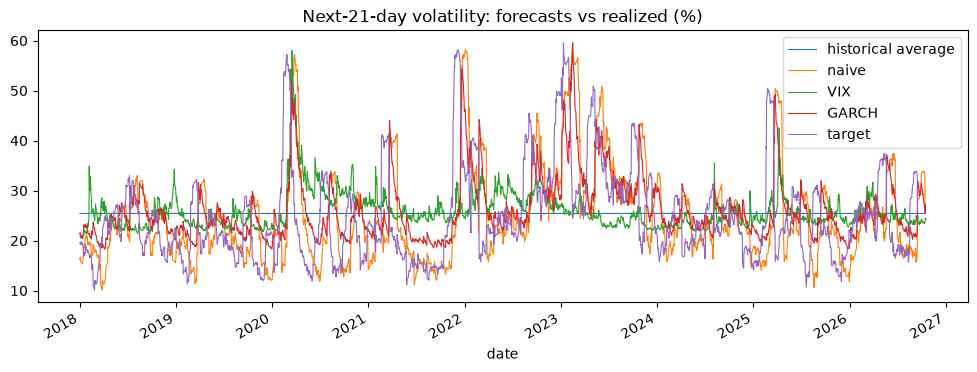

In [7]:
test = forecasts["from 2003"].join(dataset["target"])
test.plot(figsize=(12, 4), lw=0.8, title="Next-21-day volatility: forecasts vs realized (%)")
plt.show()

## Findings

- **Test-period levels.** BIST's realized volatility over the next 21 days averaged 24.9% in 2018–2026, with a standard deviation of 9.5 points.
- **The historical average is a tough baseline.** Trained from 2003, this constant forecast has an RMSE of 9.49, slightly better than GARCH's 9.52. Volatility in 2018–2026 keeps falling back to its long-run level, so ignoring recent volatility costs little on RMSE.
- **GARCH is still the best baseline overall.** It has the lowest MAE and QLIKE in both scenarios (7.2 and 0.247 from 2003), so it does use recent volatility well.
- **Training from 2003 beats training from 1997.** With the crisis years included, the fitted baselines over-forecast: the historical average by 7.8 points on average, VIX by 7.0 and GARCH by 2.7. From 2003, those biases shrink to 0.5, 0.9 and 1.2, and every score improves.
- **Naive is unbiased but late.** Its average error is close to 0, but it has the worst QLIKE (0.402) in both scenarios, and its RMSE (11.2) is worse than the 2003 historical average's. It only catches up with a volatility spike after the spike has happened.